# 5.5. Preguntas de análisis (2 puntos)


En el notebook número 1 identificamos que la base de datos contiene información sobre los incidentes reportados al C5 de la Ciudad de México (CDMX), con un total de 124.3 mil filas y 14 columnas.

Uno de los principales hallazgos fue que todos los folios son únicos, ya que, al comparar el número total de registros con el número de valores únicos de la columna `folio`, obtuvimos el mismo resultado. Este hallazgo es relevante por su relación con la columna `codigo_cierre`, que permite identificar si un reporte corresponde a un incidente distinto o a uno previamente registrado. Esto se debe a que varias personas pueden reportar un mismo incidente, por lo que los registros duplicados se identifican con la letra "D" en dicha columna, aunque cada reporte conserve un folio único.

En relación con algunas variables categóricas, como `tipo_incidente_c4`, `incidente_c4`, `clas_con_f_alarma` y `tipo_entrada`, no identificamos registros extraños. Sin embargo, algunas categorías cuentan con muy pocas observaciones. Por ejemplo, en la variable de tipo de incidente, únicamente se registraron 22 observaciones correspondientes a incidentes ferroviarios. 

Respecto a los valores faltantes, únicamente las columnas `alcaldia_catalogo`, `colonia_catalogo` y `alcaldia_cierre` presentaron valores ausentes. En el caso de `alcaldia_catalogo`, esto se debe a que dicha información comenzó a generarse después de diciembre de 2023, por lo que los valores faltantes se concentran principalmente en 2022. Consideramos que una posible alternativa sería utilizar las coordenadas geográficas para recuperar esta información. No obstante, algunos registros de la variable `alcaldia_cierre` podrían permanecer como valores ausentes.

Además, detectamos que todas las columnas eran de tipo *string*, con excepción de `latitud` y `longitud`. Esto representaba un problema para las variables que registran las fechas y horas de creación y cierre de los reportes, por lo que se convirtieron a un formato de fecha y hora adecuado.

A partir de estas transformaciones, también generamos nuevas variables, como la hora, el día, el mes y el año, así como el tiempo transcurrido, en minutos, entre la creación y el cierre de cada reporte. Estas variables permitirán analizar los patrones temporales de los incidentes y los tiempos de atención.

Durante el perfilado también identificamos el número de categorías únicas de cada columna, lo cual nos permitió detectar posibles inconsistencias. Por ejemplo, las variables relacionadas con las alcaldías presentaron 16 categorías, lo que coincide con el número de demarcaciones territoriales de la CDMX.

Finalmente, para verificar que las ubicaciones de los incidentes correspondieran al territorio de la CDMX, utilizamos las coordenadas de latitud y longitud. 



**Preguntas** 

- ¿Porcentaje de incidentes distintos que se reportan mensualmente? 
- ¿Cuál es la composición mensual de los incidentes distintos?
- ¿En qué alcaldías se registra el mayor número de incidentes?
- ¿Cuál es el tiempo promedio de atención cuando un reporte es afirmativo por alcaldía?
- ¿Qué días de la semana se registra el mayor número de incidentes en la CDMX?


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd
url = "https://raw.githubusercontent.com/ElenaVillano/databases/refs/heads/main/db_falsas_alarmas.csv"
df = pd.read_csv(url)
df.head(1)

,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud
0,C5/20220923/04016,2022-09-23 18:38:34,2022-09-23 22:22:27,Accidente,Choque sin lesionados,VENUSTIANO CARRANZA,A,EMERGENCIA,LLAMADA DEL 911,VENUSTIANO CARRANZA,Venustiano Carranza,20 De Noviembre,-99.108352,19.44392


In [4]:
df['cordenada_fuera_cdmx'] = ~(df['latitud'].between(19.0482, 19.5928) &df['longitud'].between(-99.3649, -98.9403))
df = df[df['cordenada_fuera_cdmx']==False]

In [5]:
## Corrección de las fechas 
df['fecha_hora_creacion'] = pd.to_datetime(df['fecha_hora_creacion'],format='%Y-%m-%d %H:%M:%S')

In [6]:
df['fecha_hora_cierre'] = pd.to_datetime(df['fecha_hora_cierre'],format='%Y-%m-%d %H:%M:%S')

In [7]:
df['hora'] = df['fecha_hora_creacion'].dt.hour
df['dia'] = df['fecha_hora_creacion'].dt.day
df['mes'] = df['fecha_hora_creacion'].dt.month
df['año'] = df['fecha_hora_creacion'].dt.year
df['tiempo_minutos'] = (df['fecha_hora_cierre'] - df['fecha_hora_creacion']).dt.total_seconds() / 60

In [8]:
dias = { 0: 'Lunes',1: 'Martes',2: 'Miércoles',3: 'Jueves',4: 'Viernes',5: 'Sábado',6: 'Domingo'}
df['dia_semana'] = (df['fecha_hora_creacion'].dt.dayofweek.map(dias))

C:\Users\cinti\AppData\Local\Temp\ipykernel_20348\3185948165.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['dia_semana'] = (df['fecha_hora_creacion'].dt.dayofweek.map(dias))


In [9]:
df.columns

Index(['folio', 'fecha_hora_creacion', 'fecha_hora_cierre',
       'tipo_incidente_c4', 'incidente_c4', 'alcaldia_inicio', 'codigo_cierre',
       'clas_con_f_alarma', 'tipo_entrada', 'alcaldia_cierre',
       'alcaldia_catalogo', 'colonia_catalogo', 'longitud', 'latitud',
       'cordenada_fuera_cdmx', 'hora', 'dia', 'mes', 'año', 'tiempo_minutos',
       'dia_semana'],
      dtype='str')

In [10]:
# Crear periodo mensual
df['periodo'] = df['fecha_hora_creacion'].dt.to_period('M')

In [11]:
df['duplicado'] = (df['codigo_cierre'] == 'D')

In [12]:
df['duplicado'].unique()

array([False,  True])

# Pregunta 1 Porcentaje de reportes distintos mensualmente

In [26]:
tabla_mensual = (
    df.groupby('periodo').agg(
        total_reportes=('folio', 'size'),
        duplicados=('duplicado', 'sum')
    )
    .reset_index()
)


tabla_mensual['incidentes_distintos'] = (
    tabla_mensual['total_reportes']
    - tabla_mensual['duplicados']
)

tabla_mensual['porcentaje_incidentes_distintos'] = (
    100 * tabla_mensual['incidentes_distintos']
    / tabla_mensual['total_reportes']
).round(2)

tabla_mensual

,periodo,total_reportes,duplicados,incidentes_distintos,porcentaje_incidentes_distintos
0,2021-12,17,6,11,64.71
1,2022-01,3615,1593,2022,55.93
2,2022-02,3899,1743,2156,55.30
3,2022-03,4727,1966,2761,58.41
4,2022-04,4481,1912,2569,57.33
5,2022-05,5108,2258,2850,55.79
6,2022-06,4685,2007,2678,57.16
7,2022-07,4737,2036,2701,57.02
8,2022-08,4763,2037,2726,57.23
9,2022-09,5347,2401,2946,55.10


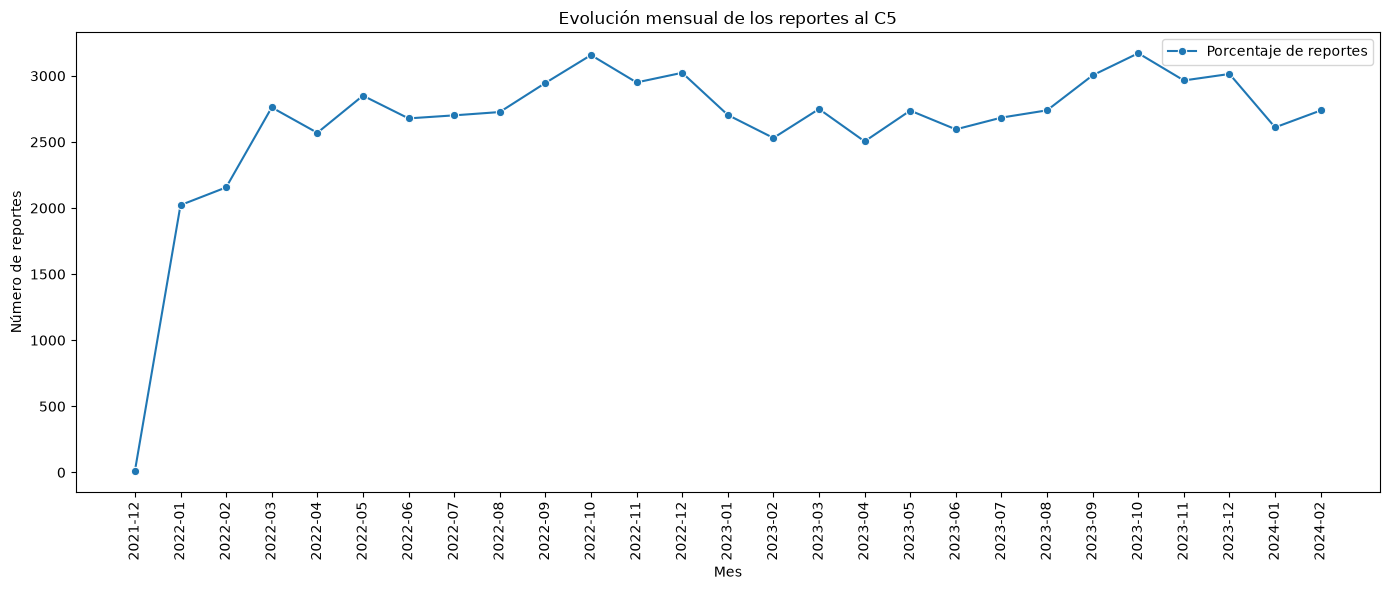

In [27]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=tabla_mensual,
    x=tabla_mensual['periodo'].astype(str),
    y='incidentes_distintos',
    marker='o',
    label='Porcentaje de reportes'
)


plt.title('Evolución mensual de los reportes al C5')
plt.xlabel('Mes')
plt.ylabel('Número de reportes')
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

# Pregunta 2 

In [15]:
composicion = (
    df.loc[~df['duplicado']]
    .groupby(['periodo', 'tipo_incidente_c4'])
    .size()
    .reset_index(name='frecuencia')
)

composicion['porcentaje'] = (
    100 * composicion['frecuencia']
    / composicion.groupby('periodo')['frecuencia'].transform('sum')
).round(2)

display(composicion)

,periodo,tipo_incidente_c4,frecuencia,porcentaje
0,2021-12,Accidente,11,100.00
1,2022-01,Accidente,1819,89.96
2,2022-01,Cadáver,8,0.40
3,2022-01,Lesionado,188,9.30
4,2022-01,Mi Calle,6,0.30
...,...,...,...,...
111,2024-01,Cadáver,5,0.19
112,2024-01,Lesionado,236,9.04
113,2024-02,Accidente,2483,90.69
114,2024-02,Cadáver,15,0.55


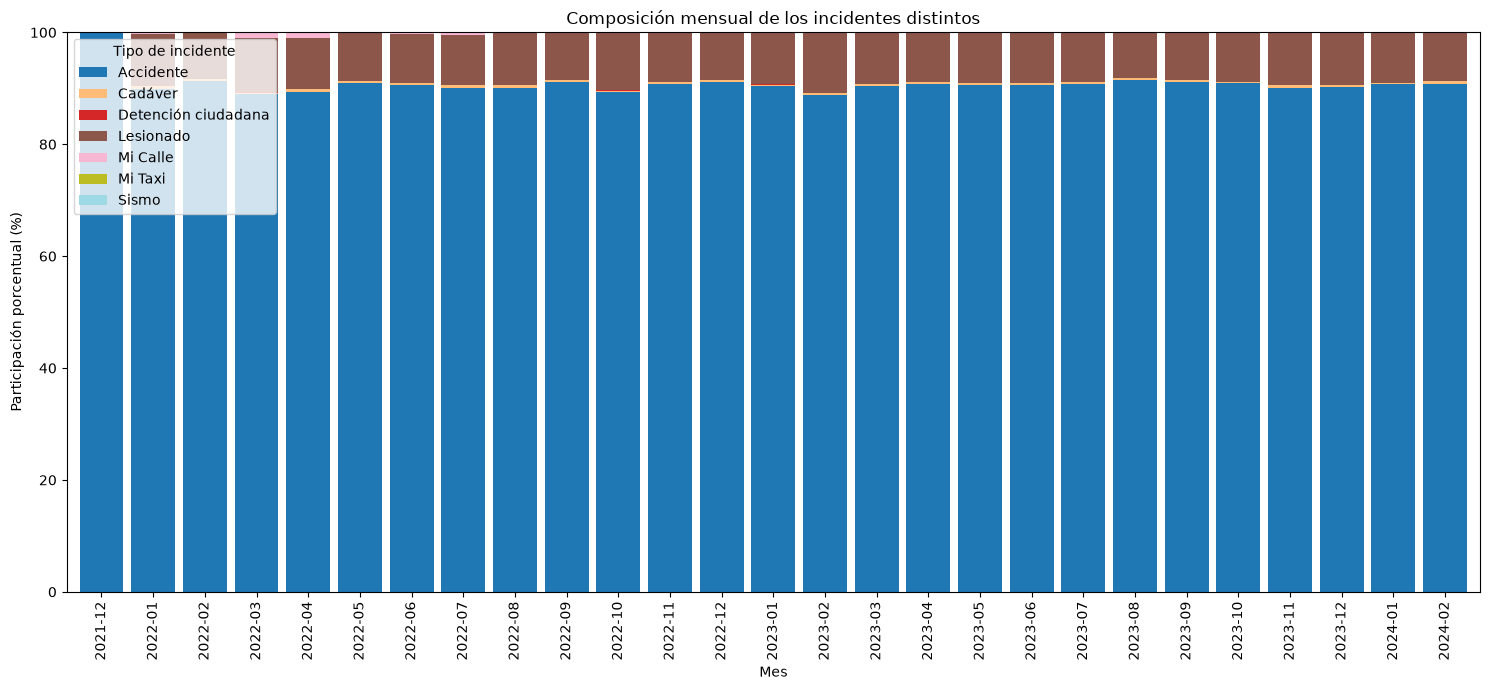

In [16]:
tabla_composicion = composicion.pivot(
    index='periodo',
    columns='tipo_incidente_c4',
    values='porcentaje'
).fillna(0)

tabla_composicion.index = tabla_composicion.index.astype(str)

tabla_composicion.plot(
    kind='bar',
    stacked=True,
    figsize=(15, 7),
    colormap='tab20',
    width=0.85
)

plt.title('Composición mensual de los incidentes distintos')
plt.xlabel('Mes')
plt.ylabel('Participación porcentual (%)')
plt.legend(
    title='Tipo de incidente',
    loc='upper left'
)
plt.tight_layout()
plt.show()

# Pregunta 3: alcaldias con más delitos iniciados

In [17]:
tabla_alcaldias = (
    df.loc[~df['duplicado']]
    .groupby('alcaldia_inicio')
    .size()
    .reset_index(name='incidentes')
    .sort_values('incidentes', ascending=False)
)

tabla_alcaldias['porcentaje'] = (
    100 * tabla_alcaldias['incidentes']
    / tabla_alcaldias['incidentes'].sum()
).round(2)

display(tabla_alcaldias)

,alcaldia_inicio,incidentes,porcentaje
8,IZTAPALAPA,11542,16.19
5,CUAUHTEMOC,7854,11.02
6,GUSTAVO A. MADERO,7721,10.83
14,VENUSTIANO CARRANZA,5182,7.27
3,COYOACAN,5034,7.06
2,BENITO JUAREZ,5032,7.06
13,TLALPAN,4984,6.99
0,ALVARO OBREGON,4975,6.98
10,MIGUEL HIDALGO,4673,6.55
7,IZTACALCO,3301,4.63


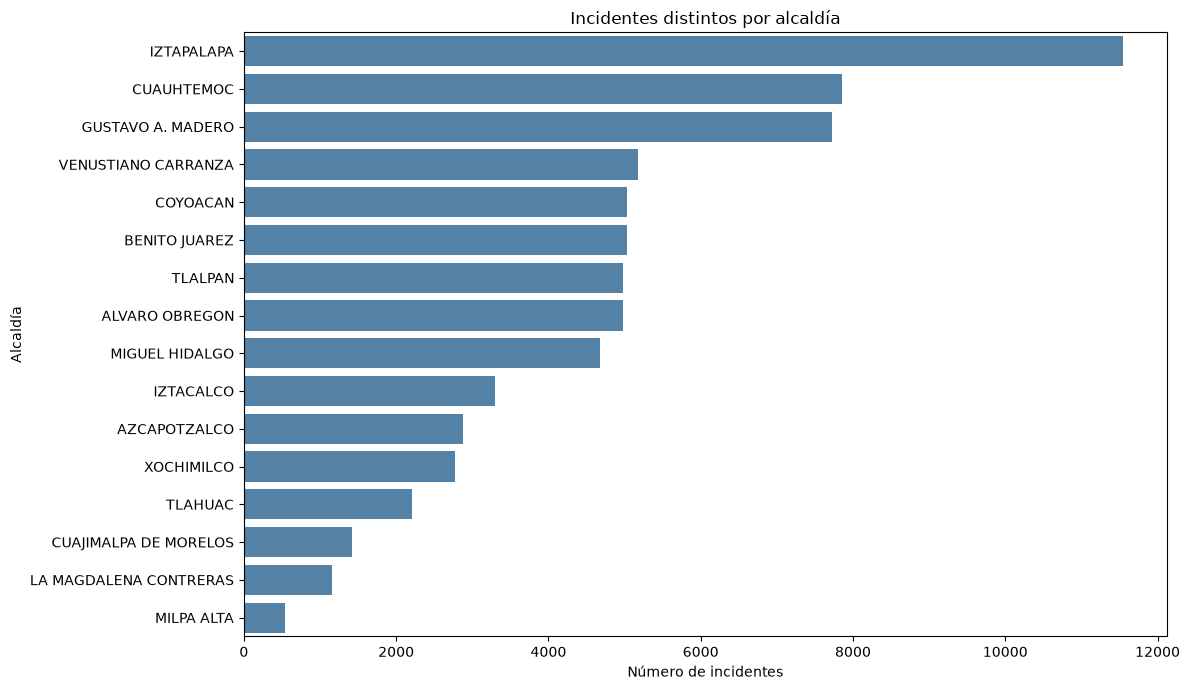

In [18]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=tabla_alcaldias,
    x='incidentes',
    y='alcaldia_inicio',
    color='steelblue'
)

plt.title('Incidentes distintos por alcaldía')
plt.xlabel('Número de incidentes')
plt.ylabel('Alcaldía')
plt.tight_layout()
plt.show()

# Pregunta 4 : tiempo promedio cuando el incidente es afirmativo

In [19]:
tabla_afirmativos = (
    df[df['codigo_cierre'] == 'A']
    .groupby('alcaldia_inicio')
    .agg(
        reportes=('folio', 'count'),
        tiempo_promedio=('tiempo_minutos', 'mean')
    )
    .round(2)
    .sort_values('tiempo_promedio', ascending=False)
    .reset_index()
)

display(tabla_afirmativos)

,alcaldia_inicio,reportes,tiempo_promedio
0,BENITO JUAREZ,3369,343.77
1,COYOACAN,3278,341.61
2,TLALPAN,2912,337.02
3,MILPA ALTA,308,334.84
4,IZTAPALAPA,6768,333.65
5,XOCHIMILCO,1417,331.01
6,VENUSTIANO CARRANZA,3459,329.65
7,GUSTAVO A. MADERO,4971,327.67
8,TLAHUAC,1448,326.01
9,CUAUHTEMOC,5934,324.58


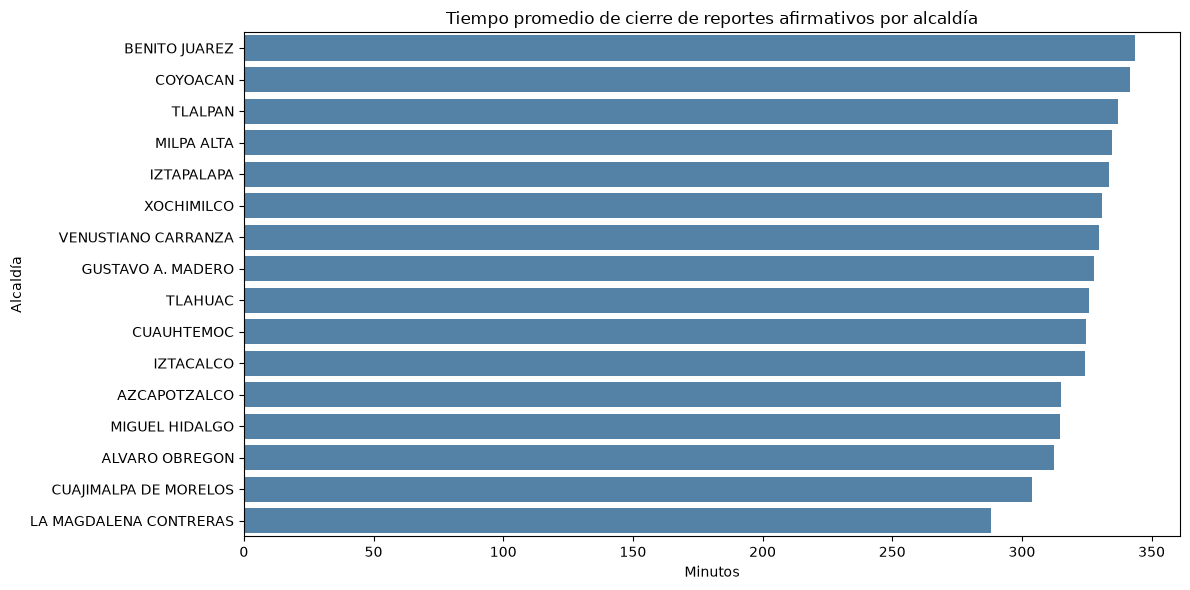

In [20]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=tabla_afirmativos,
    x='tiempo_promedio',
    y='alcaldia_inicio',
    color='steelblue'
)

plt.title('Tiempo promedio de cierre de reportes afirmativos por alcaldía')
plt.xlabel('Minutos')
plt.ylabel('Alcaldía')
plt.tight_layout()
plt.show()

# Pregunta 5 día de la semana con más incidentes

In [24]:
orden_dias = [
    'Lunes', 'Martes', 'Miércoles', 'Jueves',
    'Viernes', 'Sábado', 'Domingo'
]

tabla_dias = (
    df[df['codigo_cierre'] != 'D']
    .groupby('dia_semana')
    .size()
    .reindex(orden_dias)
    .reset_index(name='incidentes')
)

display(tabla_dias)

,dia_semana,incidentes
0,Lunes,9220
1,Martes,9681
2,Miércoles,9803
3,Jueves,9896
4,Viernes,11471
5,Sábado,11296
6,Domingo,9927


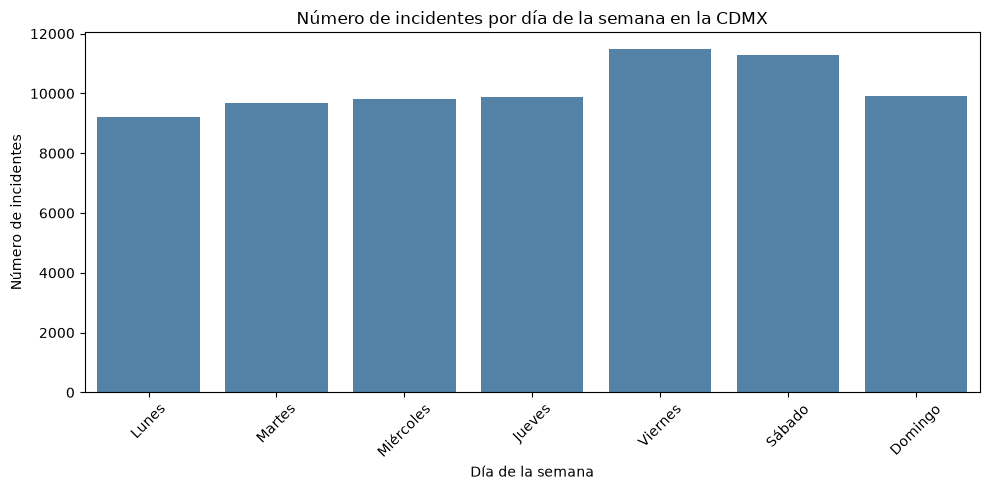

In [25]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tabla_dias,
    x='dia_semana',
    y='incidentes',
    color='steelblue'
)

plt.title('Número de incidentes por día de la semana en la CDMX')
plt.xlabel('Día de la semana')
plt.ylabel('Número de incidentes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()